# Sección 5.6 — Modelado del espacio experimental: RSM vs Proceso Gaussiano

Este notebook reproduce exclusivamente el análisis correspondiente a la sección 5.6 de la tesis.

Se emplean los **13 experimentos del diseño Box–Behnken** para ajustar:

1. una **Metodología de Superficie de Respuesta (RSM)** cuadrática;
2. un **Proceso Gaussiano (GP)** con kernel Matérn 5/2;
3. la **incertidumbre predictiva** del GP.

Para facilitar la visualización tridimensional de un problema con tres factores, se representa el plano **pH–Sacarosa** manteniendo constante:

\[
\log_{10}(\text{inóculo}) = 6.7
\]

No se incluye Optimización Bayesiana, Expected Improvement ni los datos de expansión del dominio, ya que corresponden a la sección 5.7.

## 1. Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

## 2. Datos experimentales Box–Behnken

Los datos se conservan exactamente como aparecen en el script original de análisis.

In [ ]:
variables = ["pH", "Sacarosa", "Log_inoc"]

df = pd.DataFrame({
    "pH": [
        4.5, 6.5, 4.5, 6.5,
        4.5, 6.5, 4.5, 6.5,
        5.5, 5.5, 5.5, 5.5,
        5.5
    ],
    "Sacarosa": [
        1.0, 1.0, 4.0, 4.0,
        2.5, 2.5, 2.5, 2.5,
        1.0, 4.0, 1.0, 4.0,
        2.5
    ],
    "Log_inoc": [
        6.70, 6.70, 6.70, 6.70,
        5.00, 5.00, 7.00, 7.00,
        5.00, 5.00, 7.00, 7.00,
        6.70
    ],
    "CisZ": [
        0.231517, 0.1556, 0.15039, 0.0863,
        0.1284, 0.094, 0.1153, 0.1135,
        0.090, 0.0688, 0.1315, 0.1420,
        0.0939
    ] # mg/L
})

df

,pH,Sacarosa,Log_inoc,CisZ
0,4.5,1.0,6.7,0.231517
1,6.5,1.0,6.7,0.155600
2,4.5,4.0,6.7,0.150390
3,6.5,4.0,6.7,0.086300
4,4.5,2.5,5.0,0.128400
5,6.5,2.5,5.0,0.094000
6,4.5,2.5,7.0,0.115300
7,6.5,2.5,7.0,0.113500
8,5.5,1.0,5.0,0.090000
9,5.5,4.0,5.0,0.068800


## 3. Dominio experimental y escalado para el GP

El RSM se ajusta directamente con las variables en sus unidades originales.

Para el Proceso Gaussiano, los factores se transforman al intervalo \([0,1]\) mediante un escalado min–max definido por los límites del diseño Box–Behnken.

In [ ]:
rangos = {
    "pH": (4.5, 6.5),
    "Sacarosa": (1.0, 4.0),
    "Log_inoc": (5.0, 7.0)
}

def escalar(X):
    Xs = X.copy()

    for variable in variables:
        minimo, maximo = rangos[variable]
        Xs[variable] = (
            (X[variable] - minimo) /
            (maximo - minimo)
        )

    return Xs

## 4. Ajuste del modelo RSM cuadrático

Se utiliza un polinomio de segundo orden con términos:

- lineales;
- cuadráticos;
- de interacción de dos factores.

La forma general corresponde a:

\[
y =
\beta_0+
\sum_i \beta_i x_i+
\sum_i \beta_{ii}x_i^2+
\sum_{i<j}\beta_{ij}x_ix_j
\]

In [ ]:
X = df[variables]
y = df["CisZ"]

modelo_rsm = Pipeline([
    ("poly", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("reg", LinearRegression())
])

modelo_rsm.fit(X, y)

y_pred_rsm = modelo_rsm.predict(X)

r2_rsm = r2_score(y, y_pred_rsm)
rmse_rsm = np.sqrt(
    mean_squared_error(y, y_pred_rsm)
)

print("RSM cuadrático")
print(f"R²   = {r2_rsm:.4f}")
print(f"RMSE = {rmse_rsm:.2f}")

RSM cuadrático
R²   = 0.7315
RMSE = 0.02


## 5. Ajuste del Proceso Gaussiano

Se emplea un kernel compuesto por:

\[
k(\mathbf{x},\mathbf{x}')
=
\sigma_f^2
k_{\mathrm{Matérn}\,5/2}(\mathbf{x},\mathbf{x}')
+
\sigma_n^2\delta_{\mathbf{x},\mathbf{x}'}
\]

El kernel Matérn utiliza una longitud característica independiente para cada factor experimental.

In [ ]:

Xs = escalar(df[variables]).values
ys = df["CisZ"].values

kernel = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(0.001, 1000.0)
    )
    *
    Matern(
        length_scale=[0.35, 0.35, 0.35],
        length_scale_bounds=(0.005, 5.0),
        nu=2.5
    )
    +
    WhiteKernel(
        noise_level=0.01,
        noise_level_bounds=(1e-6, 1.0)
    )
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,
    n_restarts_optimizer=50,
    random_state=42
)

gp.fit(Xs, ys)

print("Kernel optimizado:")
print(gp.kernel_)

Kernel optimizado:
0.69**2 * Matern(length_scale=[0.0132, 1.17, 0.00837], nu=2.5) + WhiteKernel(noise_level=0.498)


## 6. Malla de predicción para las figuras de la tesis

El problema experimental tiene tres factores. Para visualizar las superficies en dos y tres dimensiones se fija:

**Log_inoc = 6.7**

y se construye una malla sobre pH y concentración de sacarosa.

In [ ]:
log_inoc_fijo = 6.7
n_malla = 160

ph = np.linspace(
    rangos["pH"][0],
    rangos["pH"][1],
    n_malla
)

sacarosa = np.linspace(
    rangos["Sacarosa"][0],
    rangos["Sacarosa"][1],
    n_malla
)

PH, SAC = np.meshgrid(ph, sacarosa)

malla = pd.DataFrame({
    "pH": PH.ravel(),
    "Sacarosa": SAC.ravel(),
    "Log_inoc": log_inoc_fijo
})

# Predicción RSM
Z_rsm = modelo_rsm.predict(
    malla[variables]
).reshape(PH.shape)

# Predicción GP
malla_escalada = escalar(malla).values

mu_gp, sigma_gp = gp.predict(
    malla_escalada,
    return_std=True
)

Z_gp = mu_gp.reshape(PH.shape)
Z_sigma = sigma_gp.reshape(PH.shape)

# Puntos experimentales que pertenecen exactamente al corte
df_corte = df[
    np.isclose(
        df["Log_inoc"],
        log_inoc_fijo,
        atol=1e-6
    )
].copy()

df_corte

,pH,Sacarosa,Log_inoc,CisZ
0,4.5,1.0,6.7,0.231517
1,6.5,1.0,6.7,0.155600
2,4.5,4.0,6.7,0.150390
3,6.5,4.0,6.7,0.086300
12,5.5,2.5,6.7,0.093900


## 7. Figura — Superficie RSM

Esta figura corresponde al ajuste cuadrático tradicional sobre el plano pH–Sacarosa con Log_inoc = 6.7.

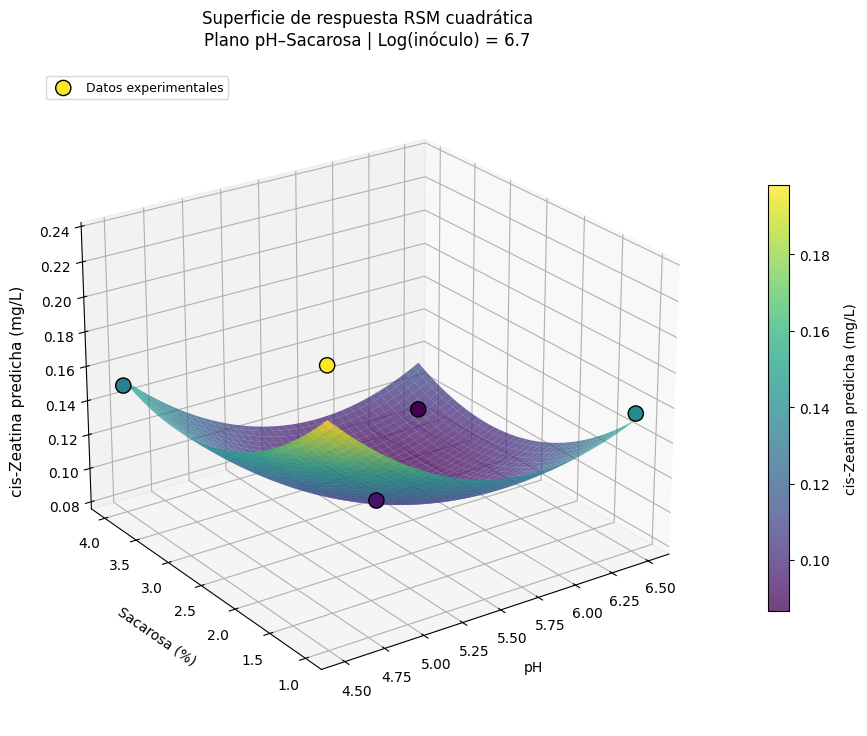

In [ ]:
"""fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    PH,
    SAC,
    Z_rsm,
    cmap="viridis",
    alpha=0.75,
    edgecolor="none"
)

ax.scatter(
    df_corte["pH"],
    df_corte["Sacarosa"],
    df_corte["CisZ"],
    c=df_corte["CisZ"],
    cmap="viridis",
    s=120,
    edgecolor="black",
    depthshade=False,
    label="Datos experimentales"
)

ax.set_xlabel("pH")
ax.set_ylabel("Sacarosa (%)")
ax.set_zlabel("cis-Zeatina predicha (µg/L)")

ax.set_title(
    "Superficie de respuesta RSM cuadrática\n"
    "Plano pH–Sacarosa | Log(inóculo) = 6.7"
)

barra = fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    pad=0.10
)
barra.set_label("cis-Zeatina predicha (µg/L)")

ax.legend()
ax.view_init(elev=24, azim=235)

plt.tight_layout()
plt.show()"""

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

# Superficie RSM
superficie = ax.plot_surface(
    PH,
    SAC,
    Z_rsm,
    cmap="viridis",
    alpha=0.75,
    edgecolor="none"
)

# Datos experimentales
ax.scatter(
    df_corte["pH"],
    df_corte["Sacarosa"],
    df_corte["CisZ"],
    c=df_corte["CisZ"],
    cmap="viridis",
    s=120,
    edgecolor="black",
    depthshade=False,
    label="Datos experimentales"
)

# Etiquetas de los ejes X e Y
ax.set_xlabel("pH", labelpad=10)
ax.set_ylabel("Sacarosa (%)", labelpad=10)

# Se elimina el zlabel del sistema 3D para evitar que se corte
ax.set_zlabel("")

# Etiqueta manual del eje Z
fig.text(
    0.095,
    0.50,
    "cis-Zeatina predicha (mg/L)",
    rotation=90,
    va="center",
    ha="center",
    fontsize=11
)

# Título
ax.set_title(
    "Superficie de respuesta RSM cuadrática\n"
    "Plano pH–Sacarosa | Log(inóculo) = 6.7",
    pad=18
)

# Barra de color
barra = fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    pad=0.08
)

barra.set_label(
    "cis-Zeatina predicha (mg/L)",
    labelpad=10
)

# Leyenda
ax.legend(
    loc="upper left",
    fontsize=9
)

# Ángulo de visualización
ax.view_init(
    elev=24,
    azim=235
)

# Ajuste manual de márgenes
plt.subplots_adjust(
    left=0.08,
    right=0.90,
    bottom=0.08,
    top=0.90
)

# Guardar en alta resolución
plt.savefig(
    "RSM_superficie_BB.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15
)

plt.show()

## 8. Figura — Media posterior del Proceso Gaussiano

La superficie representa la media predictiva \(\mu(\mathbf{x})\) del GP sobre exactamente el mismo plano utilizado para el RSM.

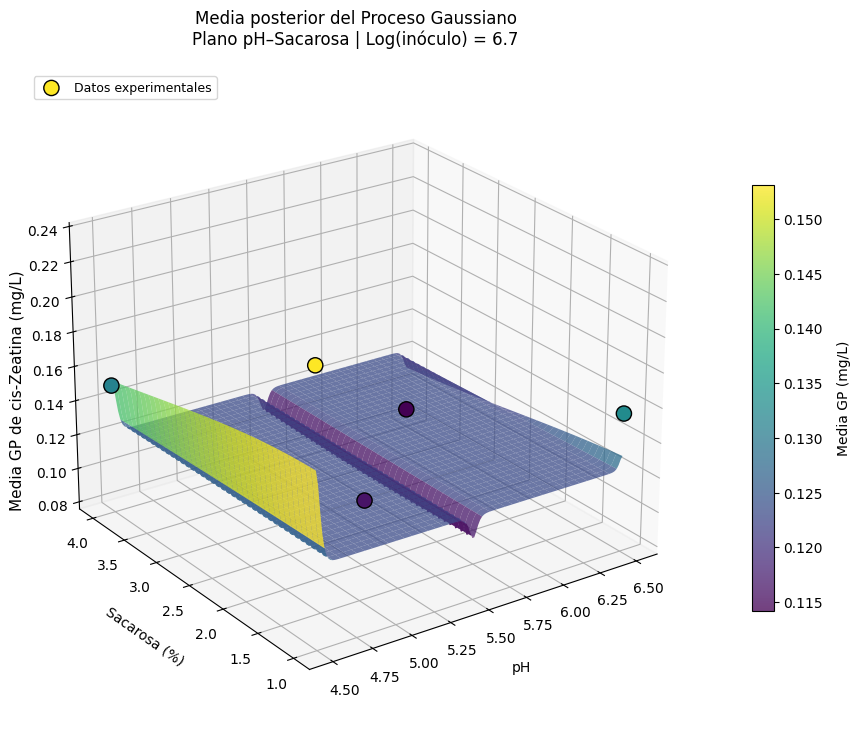

In [ ]:
"""fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    PH,
    SAC,
    Z_gp,
    cmap="viridis",
    alpha=0.75,
    edgecolor="none"
)

ax.scatter(
    df_corte["pH"],
    df_corte["Sacarosa"],
    df_corte["CisZ"],
    c=df_corte["CisZ"],
    cmap="viridis",
    s=120,
    edgecolor="black",
    depthshade=False,
    label="Datos experimentales"
)

ax.set_xlabel("pH")
ax.set_ylabel("Sacarosa (%)")
ax.set_zlabel("Media GP de cis-Zeatina (µg/L)")

ax.set_title(
    "Media posterior del Proceso Gaussiano\n"
    "Plano pH–Sacarosa | Log(inóculo) = 6.7"
)

barra = fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    pad=0.10
)
barra.set_label("Media GP (µg/L)")

ax.legend()
ax.view_init(elev=24, azim=235)

plt.tight_layout()
plt.show()"""



fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    PH,
    SAC,
    Z_gp,
    cmap="viridis",
    alpha=0.75,
    edgecolor="none"
)

ax.scatter(
    df_corte["pH"],
    df_corte["Sacarosa"],
    df_corte["CisZ"],
    c=df_corte["CisZ"],
    cmap="viridis",
    s=120,
    edgecolor="black",
    depthshade=False,
    label="Datos experimentales"
)

ax.set_xlabel("pH", labelpad=10)
ax.set_ylabel("Sacarosa (%)", labelpad=10)

# Quitamos la etiqueta Z del sistema 3D
ax.set_zlabel("")

# La colocamos manualmente como texto de la figura
fig.text(
    0.095,
    0.50,
    "Media GP de cis-Zeatina (mg/L)",
    rotation=90,
    va="center",
    ha="center",
    fontsize=11
)

ax.set_title(
    "Media posterior del Proceso Gaussiano\n"
    "Plano pH–Sacarosa | Log(inóculo) = 6.7",
    pad=18
)

barra = fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    pad=0.08
)

barra.set_label(
    "Media GP (mg/L)",
    labelpad=10
)

ax.legend(
    loc="upper left",
    fontsize=9
)

ax.view_init(
    elev=24,
    azim=235
)

# No usar tight_layout en esta figura 3D
plt.subplots_adjust(
    left=0.10,
    right=0.88,
    bottom=0.08,
    top=0.90
)

plt.savefig(
    "GP_media_BB.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()

## 9. Figura — Incertidumbre predictiva del GP

El mapa de contornos representa la desviación estándar predictiva \(\sigma(\mathbf{x})\).

Valores bajos indican regiones donde el GP posee mayor respaldo de las observaciones disponibles; valores altos indican regiones con menor soporte experimental.

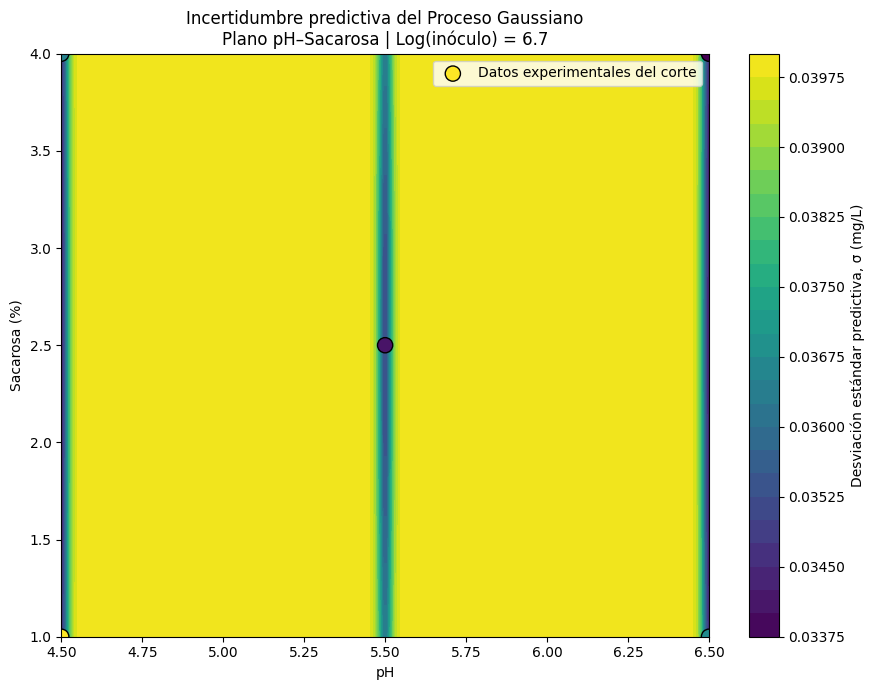

In [ ]:
plt.figure(figsize=(9, 7))

contorno = plt.contourf(
    PH,
    SAC,
    Z_sigma,
    levels=24,
    cmap="viridis"
)

barra = plt.colorbar(contorno)
barra.set_label(
    "Desviación estándar predictiva, σ (mg/L)"
)

plt.scatter(
    df_corte["pH"],
    df_corte["Sacarosa"],
    s=120,
    c=df_corte["CisZ"],
    cmap="viridis",
    edgecolor="black",
    label="Datos experimentales del corte"
)

plt.xlabel("pH")
plt.ylabel("Sacarosa (%)")

plt.title(
    "Incertidumbre predictiva del Proceso Gaussiano\n"
    "Plano pH–Sacarosa | Log(inóculo) = 6.7"
)

plt.legend()
plt.tight_layout()
plt.show()

## 10. Comparación visual compacta RSM vs GP

Esta figura es complementaria. Puede conservarse en el repositorio aunque no necesariamente deba aparecer en la tesis.

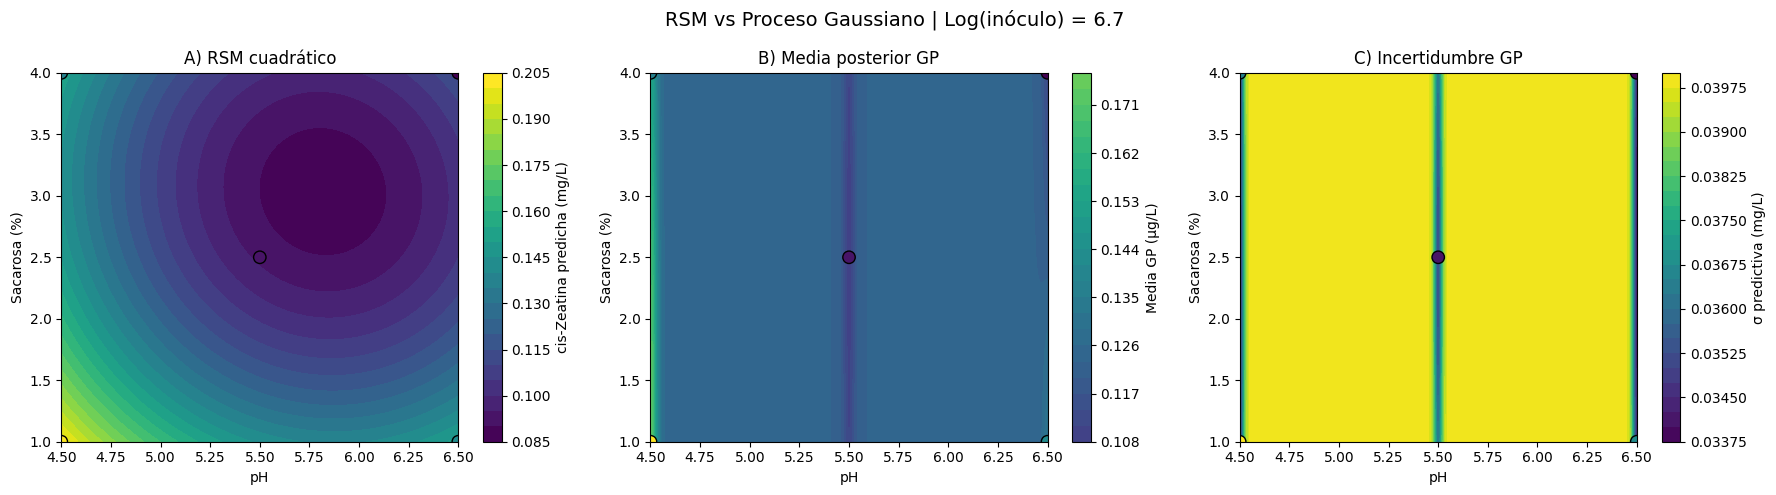

In [ ]:
vmin = min(Z_rsm.min(), Z_gp.min())
vmax = max(Z_rsm.max(), Z_gp.max())

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# RSM
c1 = axes[0].contourf(
    PH,
    SAC,
    Z_rsm,
    levels=24,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax
)
fig.colorbar(c1, ax=axes[0]).set_label(
    "cis-Zeatina predicha (mg/L)"
)

# GP
c2 = axes[1].contourf(
    PH,
    SAC,
    Z_gp,
    levels=24,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax
)
fig.colorbar(c2, ax=axes[1]).set_label(
    "Media GP (µg/L)"
)

# Incertidumbre
c3 = axes[2].contourf(
    PH,
    SAC,
    Z_sigma,
    levels=24,
    cmap="viridis"
)
fig.colorbar(c3, ax=axes[2]).set_label(
    "σ predictiva (mg/L)"
)

titulos = [
    "A) RSM cuadrático",
    "B) Media posterior GP",
    "C) Incertidumbre GP"
]

for ax, titulo in zip(axes, titulos):
    ax.scatter(
        df_corte["pH"],
        df_corte["Sacarosa"],
        s=80,
        c=df_corte["CisZ"],
        cmap="viridis",
        edgecolor="black"
    )
    ax.set_xlabel("pH")
    ax.set_ylabel("Sacarosa (%)")
    ax.set_title(titulo)

fig.suptitle(
    "RSM vs Proceso Gaussiano | Log(inóculo) = 6.7",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 11. Resumen numérico

Esta celda facilita registrar los valores principales del ajuste y verificar que el notebook se ejecutó correctamente.

In [ ]:
resumen = pd.DataFrame({
    "Métrica": [
        "Número de experimentos",
        "R² RSM",
        "RMSE RSM",
        "Log(inóculo) usado en las figuras"
    ],
    "Valor": [
        len(df),
        round(r2_rsm, 4),
        round(rmse_rsm, 2),
        log_inoc_fijo
    ]
})

display(resumen)

print("\nKernel GP optimizado:")
print(gp.kernel_)

,Métrica,Valor
0,Número de experimentos,13.0000
1,R² RSM,0.7315
2,RMSE RSM,0.0200
3,Log(inóculo) usado en las figuras,6.7000



Kernel GP optimizado:
0.69**2 * Matern(length_scale=[0.0132, 1.17, 0.00837], nu=2.5) + WhiteKernel(noise_level=0.498)


In [ ]:
# ============================================================
# Comparación del ajuste RSM vs GP
# Mismos 13 experimentos Box-Behnken
# ============================================================

# RSM
pred_rsm_ajuste = modelo_rsm.predict(X)

r2_rsm_ajuste = r2_score(y, pred_rsm_ajuste)

rmse_rsm_ajuste = np.sqrt(
    mean_squared_error(y, pred_rsm_ajuste)
)

# GP
pred_gp_ajuste, std_gp_ajuste = gp.predict(
    Xs,
    return_std=True
)

r2_gp_ajuste = r2_score(ys, pred_gp_ajuste)

rmse_gp_ajuste = np.sqrt(
    mean_squared_error(ys, pred_gp_ajuste)
)

# Resultados
print("COMPARACIÓN DEL AJUSTE RSM vs GP")
print("=" * 50)

print(
    f"RSM -> R² = {r2_rsm_ajuste:.4f} | "
    f"RMSE = {rmse_rsm_ajuste:.4f} mg/L"
)

print(
    f"GP  -> R² = {r2_gp_ajuste:.4f} | "
    f"RMSE = {rmse_gp_ajuste:.4f} mg/L"
)

COMPARACIÓN DEL AJUSTE RSM vs GP
RSM -> R² = 0.7315 | RMSE = 0.0210 mg/L
GP  -> R² = 0.7302 | RMSE = 0.0210 mg/L


In [ ]:
# ============================================================
# Comparación del ajuste RSM vs GP
# Mismos 13 experimentos Box-Behnken
# ============================================================

# RSM
pred_rsm_ajuste = modelo_rsm.predict(X)

r2_rsm_ajuste = r2_score(y, pred_rsm_ajuste)

rmse_rsm_ajuste = np.sqrt(
    mean_squared_error(y, pred_rsm_ajuste)
)

# GP
pred_gp_ajuste, std_gp_ajuste = gp.predict(
    Xs,
    return_std=True
)

r2_gp_ajuste = r2_score(ys, pred_gp_ajuste)

rmse_gp_ajuste = np.sqrt(
    mean_squared_error(ys, pred_gp_ajuste)
)

# Resultados
print("COMPARACIÓN DEL AJUSTE RSM vs GP")
print("=" * 50)

print(
    f"RSM -> R² = {r2_rsm_ajuste:.4f} | "
    f"RMSE = {rmse_rsm_ajuste:.4f} mg/L"
)

print(
    f"GP  -> R² = {r2_gp_ajuste:.4f} | "
    f"RMSE = {rmse_gp_ajuste:.4f} mg/L"
)